# Parte 1 — Dataset y preprocesamiento

Tecnicatura Universitaria en Inteligencia Artificial (FCEIA - UNR) · Computer Vision

Esta notebook documenta todo el tratamiento del dataset: elección, análisis exploratorio, detección y alineación,
control de calidad, clustering exploratorio, data augmentation, partición en splits y consideraciones éticas.
Las salidas (rostros alineados, embeddings y splits) quedan en `data/` y las reutiliza `2-train.ipynb`.

## Equipo
- Facundo Quinteros - Q-0493/6 - @FacuQuinteros03
- Roberto Lasarte - L-3370/7 - @RoberLasarte332

## Índice
0. Configuración
1. Elección del dataset
2. Análisis exploratorio (EDA)
3. Detección y alineación
4. Control de calidad y limpieza
5. Clustering exploratorio
6. Data augmentation
7. Partición de datos (splits)
8. Ética, privacidad y licencias
9. Resumen final

> **Nota sobre el orden.** El enunciado pone el control de calidad antes que la detección, pero varias reglas de calidad
> (sin rostro, más de un rostro, tamaño del rostro, blur del rostro) necesitan el resultado del detector. Por eso primero
> elegimos y corremos el detector (sección 3) y después aplicamos todas las reglas (sección 4).

## 0. Configuración

La lógica de detección, alineación y preprocesamiento vive en `src/lib/face_pipeline.py` y la de augmentation en
`src/lib/augmentation.py`. La notebook de entrenamiento y el backend (`face_service.py`) importan **los mismos módulos**:
así el rostro que ve el modelo en la app se recorta, alinea y normaliza exactamente igual que en el entrenamiento.

In [1]:
import json
import random
import sys
import time
import warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import albumentations as A
import cv2
import matplotlib.pyplot as plt
import numpy as np
import onnxruntime as ort
import pandas as pd
from IPython.display import display
from tqdm.auto import tqdm

ROOT = Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
from lib import face_pipeline as fp
from lib.augmentation import build_train_augmentation

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

FACE_SIZE = 112
DET_INPUT_SIZE = 640
DET_SCORE_THRESHOLD = 0.5
DET_PAD = 0.5  # borde negro alrededor de la imagen antes de detectar (ver sección 3.1)

DATA_DIR = ROOT / "data"
PROC_DIR = DATA_DIR / "processed"
ALIGNED_DIR = PROC_DIR / "aligned"
SPLITS_DIR = DATA_DIR / "splits"
MODELS_DIR = ROOT / "models"
for d in (PROC_DIR, ALIGNED_DIR, SPLITS_DIR):
    d.mkdir(parents=True, exist_ok=True)

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
warnings.filterwarnings("ignore", category=FutureWarning)
ort.set_default_logger_severity(3)
PROVIDERS = [p for p in ("CUDAExecutionProvider", "CPUExecutionProvider") if p in ort.get_available_providers()]
print("onnxruntime providers:", PROVIDERS)

/root/venvs/tp/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026-10-27 22:21:26.534225659 [W:onnxruntime:Default, device_discovery.cc:325 DiscoverDevicesForPlatform] GPU device discovery failed: device_discovery.cc:92 ReadFileContents Failed to open file: "/sys/class/drm/card0/device/vendor"


onnxruntime providers: ['CUDAExecutionProvider', 'CPUExecutionProvider']


In [2]:
def bgr2rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def read(path):
    return cv2.imread(str(path))


def show_grid(images, titles=None, ncols=8, size=1.8, suptitle=None):
    if len(images) == 0:
        print("(sin imágenes)")
        return
    nrows = int(np.ceil(len(images) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size * 1.2), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), range(len(images))):
        img = images[i]
        ax.imshow(bgr2rgb(img) if img.ndim == 3 else img, cmap=None if img.ndim == 3 else "gray")
        if titles is not None:
            ax.set_title(titles[i], fontsize=7)
    if suptitle:
        fig.suptitle(suptitle)
    plt.tight_layout()
    plt.show()


def to_u64(series):
    return series.to_numpy(dtype=np.int64).view(np.uint64)


def hamming_matrix(a, b):
    """Distancia de Hamming entre todos los pares de hashes de 64 bits (arrays uint64)."""
    x = (a[:, None] ^ b[None, :]).view(np.uint8).reshape(len(a), len(b), 8)
    return np.unpackbits(x, axis=2).sum(2)

## 1. Elección del dataset

Usamos **Pins Face Recognition** (Kaggle, `hereisburak/pins-face-recognition`): fotos de **105 celebridades**
recolectadas de Pinterest y ya recortadas alrededor del rostro.

**Por qué este dataset:**
- **Muchas imágenes por identidad** (ver EDA). Es lo que necesita una CNN entrenada desde cero: con 1 o 2 imágenes por
  clase (como la mayoría de LFW) no aprende nada útil.
- **Variabilidad real**: fotos de prensa, alfombra roja, escenas de películas y selfies. Hay cambios de pose,
  iluminación, expresión, maquillaje, edad (fotos de distintos años) y oclusiones (anteojos, pelo, manos).
- **Cantidad manejable** (~17.500 imágenes, 372 MB): se puede procesar entero con la GPU local (GTX 1650, 4 GB).
- **Relación con el caso de uso**: la app registra personas a partir de fotos "de la vida real" y las reconoce en fotos
  nuevas, que es el mismo tipo de imagen que trae este dataset (no son fotos de laboratorio).
- Con 105 identidades podemos separar identidades **nunca vistas** para evaluar el escenario open-set, que es el real
  de la app.

**Licencia:** Kaggle lo publica como **CC0: Public Domain**. Ojo: las fotos se tomaron de Pinterest, así que el CC0 del
que las subió no cubre los derechos de los fotógrafos ni la imagen de las personas. Lo usamos solo con fines académicos
y no redistribuimos las imágenes (ver sección 8).

**Limitaciones esperables** (las cuantificamos más abajo):
- **Sesgo demográfico**: celebridades mayormente de Hollywood, jóvenes y de piel clara. El modelo puede rendir peor
  en otros grupos.
- **Fotos "lindas"**: mucha producción, maquillaje y buena iluminación, a diferencia de una cámara de seguridad.
- **Ruido en las etiquetas**: al ser un scraping, puede haber fotos de otra persona dentro de una carpeta, o fotos con
  varias personas.
- **Recortes con poco contexto**: las imágenes ya vienen recortadas alrededor de la cara, así que en general son de
  baja resolución.
- **Solapamiento con el modelo preentrenado**: celebridades como estas probablemente aparezcan en los datos con que se
  entrenó ArcFace (WebFace600K), lo que puede inflar sus métricas en la notebook 2. Lo tenemos en cuenta al interpretar.

In [3]:
import kagglehub

RAW_DIR = Path(kagglehub.dataset_download("hereisburak/pins-face-recognition")) / "105_classes_pins_dataset"

rows = []
for d in sorted(RAW_DIR.iterdir()):
    if d.is_dir():
        for f in sorted(d.iterdir()):
            rows.append(
                {
                    "identity": d.name.removeprefix("pins_").strip(),
                    "raw_path": str(f),
                    "file": f.name,
                    "ext": f.suffix.lower(),
                    "bytes": f.stat().st_size,
                }
            )
df = pd.DataFrame(rows)
print(f"{df.identity.nunique()} identidades · {len(df)} imágenes · {df.bytes.sum() / 1e6:.0f} MB")
df.head()

105 identidades · 17534 imágenes · 389 MB


,identity,raw_path,file,ext,bytes
0,Adriana Lima,/root/.cache/kagglehub/datasets/hereisburak/pi...,Adriana Lima0_0.jpg,.jpg,95082
1,Adriana Lima,/root/.cache/kagglehub/datasets/hereisburak/pi...,Adriana Lima101_3.jpg,.jpg,35385
2,Adriana Lima,/root/.cache/kagglehub/datasets/hereisburak/pi...,Adriana Lima102_4.jpg,.jpg,10181
3,Adriana Lima,/root/.cache/kagglehub/datasets/hereisburak/pi...,Adriana Lima103_5.jpg,.jpg,19315
4,Adriana Lima,/root/.cache/kagglehub/datasets/hereisburak/pi...,Adriana Lima104_6.jpg,.jpg,5150


## 2. Análisis exploratorio (EDA)

### 2.1 Imágenes por identidad

,count,mean,std,min,25%,50%,75%,max
imágenes por identidad,105.0,166.99,34.129,86.0,141.0,169.0,192.0,237.0


Relación máx / mín: 2.76


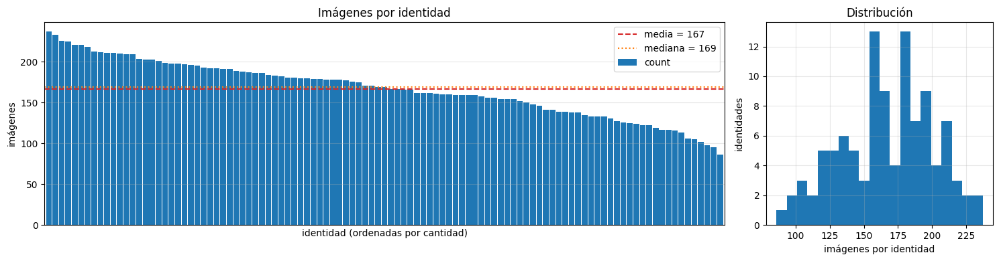

Más imágenes: Leonardo DiCaprio (237), Robert Downey Jr (233), Katherine Langford (226), Alexandra Daddario (225), elizabeth olsen (221)
Menos imágenes: Morgan Freeman (105), Brian J. Smith (102), Cristiano Ronaldo (98), Mark Zuckerberg (95), Lionel Messi (86)


In [4]:
counts = df.identity.value_counts()
display(counts.describe().to_frame("imágenes por identidad").T)
print(f"Relación máx / mín: {counts.max() / counts.min():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [3, 1]})
counts.plot.bar(ax=axes[0], width=0.9, color="tab:blue")
axes[0].axhline(counts.mean(), color="tab:red", ls="--", label=f"media = {counts.mean():.0f}")
axes[0].axhline(counts.median(), color="tab:orange", ls=":", label=f"mediana = {counts.median():.0f}")
axes[0].set_xticks([])
axes[0].set_xlabel("identidad (ordenadas por cantidad)")
axes[0].set_ylabel("imágenes")
axes[0].set_title("Imágenes por identidad")
axes[0].legend()
axes[1].hist(counts, bins=20, color="tab:blue")
axes[1].set_xlabel("imágenes por identidad")
axes[1].set_ylabel("identidades")
axes[1].set_title("Distribución")
plt.tight_layout()
plt.show()

print("Más imágenes:", ", ".join(f"{k} ({v})" for k, v in counts.head(5).items()))
print("Menos imágenes:", ", ".join(f"{k} ({v})" for k, v in counts.tail(5).items()))

**Interpretación.** Todas las identidades tienen bastantes imágenes: mínimo 86 (Lionel Messi), mediana 169, máximo 237
(Leonardo DiCaprio). El desbalance es **moderado**: la identidad más grande tiene 2,8 veces más fotos que la más chica.
No es el desbalance extremo de LFW (miles de personas con 1 sola foto), así que todas las clases tienen ejemplos
suficientes para entrenar. Igual lo tenemos en cuenta en la sección 6.

### 2.2 Formato, canales y archivos corruptos

Leemos todas las imágenes una vez. Además del tamaño, calculamos brillo (media de gris), contraste (desvío de gris) y
una medida de "colorido" (diferencia media entre canales): si es casi 0, la imagen está en blanco y negro aunque tenga
3 canales.

In [5]:
def scan(path):
    img = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    if img is None:
        return {"readable": False}
    channels = 1 if img.ndim == 2 else img.shape[2]
    if channels == 3:
        bgr = img
    else:
        bgr = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR if channels == 1 else cv2.COLOR_BGRA2BGR)
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    b, g, r = [c.astype(np.int16) for c in cv2.split(bgr)]
    return {
        "readable": True,
        "height": img.shape[0],
        "width": img.shape[1],
        "channels": channels,
        "brightness": float(gray.mean()),
        "contrast": float(gray.std()),
        "colorfulness": float((np.abs(r - g) + np.abs(g - b)).mean()),
    }


with ThreadPoolExecutor(8) as ex:
    scan_rows = list(tqdm(ex.map(scan, df.raw_path), total=len(df), desc="leyendo imágenes"))
df = pd.concat([df, pd.DataFrame(scan_rows)], axis=1)
df["grayscale_content"] = df.colorfulness < 3

summary = pd.DataFrame(
    {
        "valor": [
            ", ".join(f"{k}: {v}" for k, v in df.ext.value_counts().items()),
            int((~df.readable).sum()),
            ", ".join(f"{int(k)} canales: {v}" for k, v in df.channels.value_counts().items()),
            int(df.grayscale_content.sum()),
        ]
    },
    index=["extensiones", "archivos que no abren", "canales", "imágenes en blanco y negro (3 canales iguales)"],
)
display(summary)

leyendo imágenes:   0%|          | 0/17534 [00:00<?, ?it/s]

leyendo imágenes:   1%|          | 111/17534 [00:00<00:22, 773.03it/s]

leyendo imágenes:   1%|          | 189/17534 [00:00<00:32, 525.65it/s]

leyendo imágenes:   1%|▏         | 245/17534 [00:00<00:40, 429.92it/s]

leyendo imágenes:   2%|▏         | 319/17534 [00:00<00:34, 497.38it/s]

...

leyendo imágenes:  98%|█████████▊| 17186/17534 [00:16<00:00, 1307.64it/s]

leyendo imágenes:  99%|█████████▉| 17322/17534 [00:16<00:00, 1297.46it/s]

leyendo imágenes: 100%|█████████▉| 17481/17534 [00:16<00:00, 1372.38it/s]

leyendo imágenes: 100%|██████████| 17534/17534 [00:16<00:00, 1073.40it/s]

,valor
extensiones,.jpg: 17534
archivos que no abren,0
canales,3 canales: 17534
imágenes en blanco y negro (3 canales iguales),1267


### 2.3 Resoluciones

,count,mean,std,min,25%,50%,75%,max
width,17534.0,211.458,101.515,80.00,122.000,175.000,255.000,564.000
height,17534.0,225.721,112.818,82.00,129.000,185.000,268.000,802.000
aspect,17534.0,0.942,0.040,0.57,0.942,0.944,0.946,1.473


Imágenes con algún lado < 112px (FACE_SIZE): 2626 (15.0%)


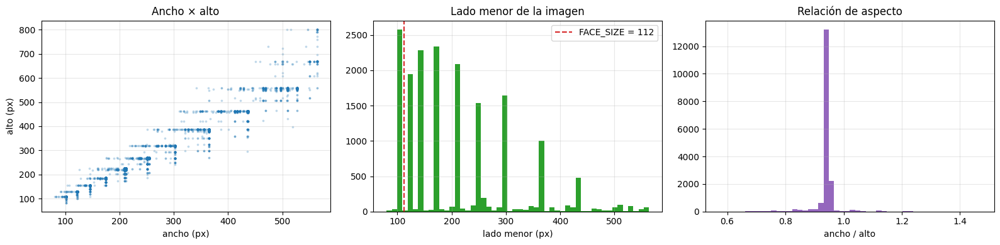

In [6]:
df["aspect"] = df.width / df.height
display(df[["width", "height", "aspect"]].describe().T)
small = (df[["width", "height"]].min(axis=1) < FACE_SIZE).sum()
print(f"Imágenes con algún lado < {FACE_SIZE}px (FACE_SIZE): {small} ({small / len(df):.1%})")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(df.width, df.height, s=3, alpha=0.2)
axes[0].set_xlabel("ancho (px)")
axes[0].set_ylabel("alto (px)")
axes[0].set_title("Ancho × alto")
axes[1].hist(df[["width", "height"]].min(axis=1), bins=50, color="tab:green")
axes[1].axvline(FACE_SIZE, color="tab:red", ls="--", label=f"FACE_SIZE = {FACE_SIZE}")
axes[1].set_xlabel("lado menor (px)")
axes[1].set_title("Lado menor de la imagen")
axes[1].legend()
axes[2].hist(df.aspect, bins=50, color="tab:purple")
axes[2].set_xlabel("ancho / alto")
axes[2].set_title("Relación de aspecto")
plt.tight_layout()
plt.show()

**Interpretación.** Son imágenes **chicas**: la mediana es 175×185 px y el 15% tiene algún lado menor a 112 px. La
relación de aspecto es casi constante (≈0,94), lo que confirma que el autor del dataset recortó todas las fotos con el
mismo criterio alrededor de la cara. Ningún archivo está corrupto y todos son JPG de 3 canales, pero el 7% (1.267)
son en realidad **blanco y negro** guardadas en RGB: es una condición de captura que vamos a analizar en el clustering.

Como las caras ocupan casi toda la imagen, el rostro alineado de 112×112 en general sale de una región de 100–200 px:
hay poco margen para bajar la resolución, y un modelo que requiera entradas grandes no tendría sentido acá.

### 2.4 Muestra visual por identidad

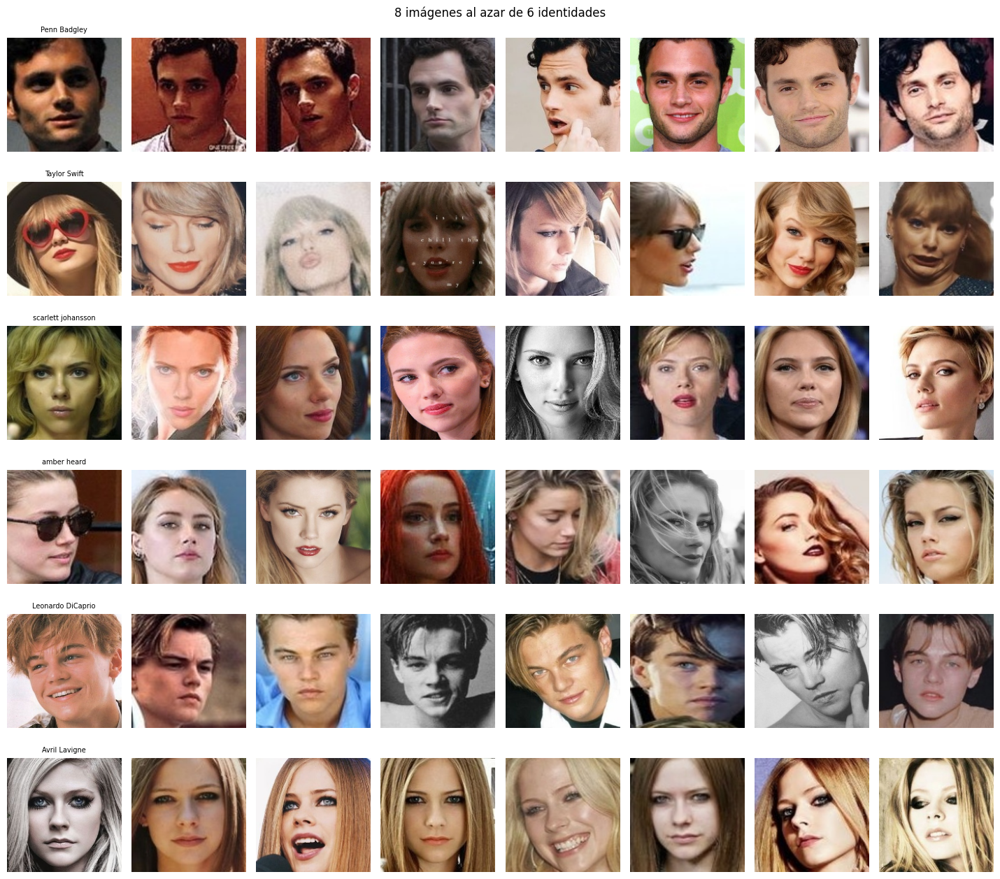

In [7]:
rng = np.random.default_rng(SEED)
sample_ids = rng.choice(sorted(df.identity.unique()), size=6, replace=False)
imgs, titles = [], []
for ident in sample_ids:
    sub = df[df.identity == ident].sample(8, random_state=SEED)
    for _, r in sub.iterrows():
        imgs.append(cv2.resize(read(r.raw_path), (160, 160)))
        titles.append(ident if len(titles) % 8 == 0 else "")
show_grid(imgs, titles, ncols=8, suptitle="8 imágenes al azar de 6 identidades")

### 2.5 Iluminación y contraste

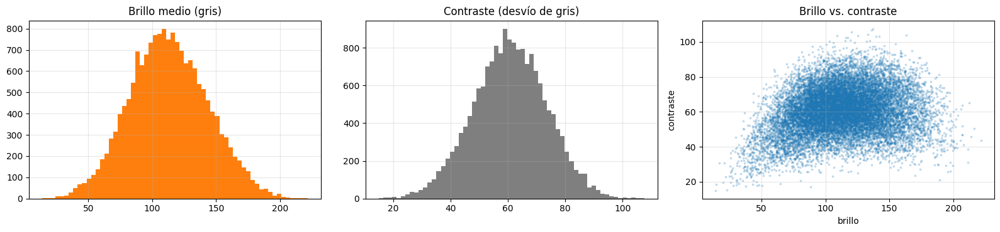

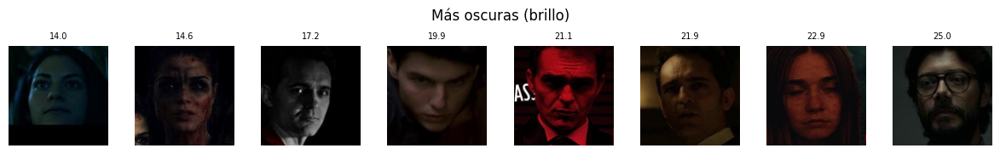

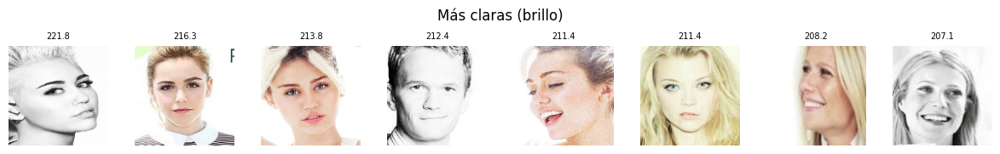

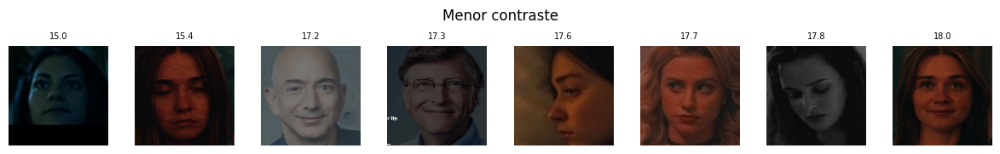

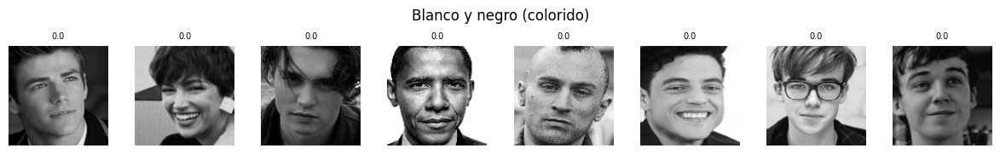

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
axes[0].hist(df.brightness, bins=60, color="tab:orange")
axes[0].set_title("Brillo medio (gris)")
axes[1].hist(df.contrast, bins=60, color="tab:gray")
axes[1].set_title("Contraste (desvío de gris)")
axes[2].scatter(df.brightness, df.contrast, s=3, alpha=0.2)
axes[2].set_xlabel("brillo")
axes[2].set_ylabel("contraste")
axes[2].set_title("Brillo vs. contraste")
plt.tight_layout()
plt.show()


def thumbs(sub, col):
    return [cv2.resize(read(p), (120, 120)) for p in sub.raw_path], [f"{v:.1f}" for v in sub[col]]


for title, sub, col in [
    ("Más oscuras (brillo)", df.nsmallest(8, "brightness"), "brightness"),
    ("Más claras (brillo)", df.nlargest(8, "brightness"), "brightness"),
    ("Menor contraste", df.nsmallest(8, "contrast"), "contrast"),
    ("Blanco y negro (colorido)", df[df.grayscale_content].sample(8, random_state=SEED), "colorfulness"),
]:
    show_grid(*thumbs(sub, col), ncols=8, size=1.5, suptitle=title)

**Interpretación.** El brillo se distribuye de forma aproximadamente normal alrededor de 110 (sobre 255) y el
contraste alrededor de 60: la mayoría son fotos bien expuestas, como es esperable en fotos de prensa y de producción.
Las colas sí existen: escenas nocturnas o de película muy oscuras, fondos blancos sobreexpuestos y fotos de bajo
contraste. El gráfico de brillo vs. contraste muestra que las fotos oscuras también tienen poco contraste: son las que
más información pierden. Estas variaciones justifican incluir cambios de brillo/contraste en la augmentation.

Variaciones cualitativas que se ven en la muestra: expresiones (sonrisas, bocas abiertas, gestos), maquillaje de
alfombra roja vs. caras lavadas, peinados y barbas que cambian entre fotos, anteojos de sol, y fotos de distintas
épocas de la vida de cada persona.

## 3. Detección y alineación

### 3.1 Elección del detector

Necesitamos un detector que además de la caja devuelva los **5 landmarks** (ojos, nariz y comisuras), porque la
alineación se hace con ellos. Candidatos:

| Detector | Landmarks | Comentario |
|---|---|---|
| Haar cascade (OpenCV) | No | Viene con OpenCV, muy rápido, pero sensible a la pose y sin landmarks: no sirve para alinear. |
| YuNet (OpenCV) | 5 | Liviano. Menos preciso con poses extremas. |
| MTCNN | 5 | Clásico, pero más lento (3 redes en cascada). |
| **SCRFD (InsightFace, `det_10g.onnx`)** | **5** | Estado del arte en WIDER FACE, ONNX en CPU, y es el detector con que se generaron los recortes de entrenamiento de ArcFace. |

Elegimos **SCRFD** por precisión, por los landmarks, y porque usar el mismo detector que el modelo preentrenado evita
que la alineación cambie entre modelos.

**Hallazgo importante.** En la primera corrida, SCRFD con la configuración de la app (entrada de 640 px) **no encontró
rostro en ~90% de las imágenes**. La causa: Pins trae recortes donde la cara ocupa casi toda la foto. El detector
reescala la imagen a 640 px, la cara queda de ~600 px, y eso supera el tamaño máximo de rostro que SCRFD aprendió a
detectar (sus *anchors* más grandes son de ~512 px). La solución es agregar un **borde negro** alrededor de la imagen
antes de detectar (`pad` en `fp.detect`), para que la cara quede de un tamaño normal, y después restar el borde a las
coordenadas. Lo mismo puede pasar en la app con una selfie muy de cerca, así que el backend usa el mismo parámetro.

Comparamos sobre una muestra de 500 imágenes: SCRFD sin borde, SCRFD con borde del 50% y el Haar cascade (la opción
"gratis" que trae OpenCV). ¿En cuántas encuentra exactamente un rostro y cuánto tarda en CPU?

In [9]:
detector = fp.load_detector(MODELS_DIR / "det_10g.onnx", DET_INPUT_SIZE, DET_SCORE_THRESHOLD)  # CPU, como en la app
haar = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")

bench = df[df.readable].sample(500, random_state=SEED)
methods = {
    "SCRFD 640 sin borde": lambda img: len(fp.detect(detector, img)),
    f"SCRFD 640 borde {DET_PAD:.0%}": lambda img: len(fp.detect(detector, img, pad=DET_PAD)),
    "Haar cascade": lambda img: len(haar.detectMultiScale(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), scaleFactor=1.1,
                                                          minNeighbors=5, minSize=(30, 30))),
}
res = {name: [] for name in methods}
times = {name: 0.0 for name in methods}
for p in tqdm(bench.raw_path, desc="comparando detectores"):
    img = read(p)
    for name, fn in methods.items():
        t0 = time.perf_counter()
        res[name].append(fn(img))
        times[name] += time.perf_counter() - t0

det_cmp = pd.DataFrame(
    {
        name: {
            "0 rostros": np.mean(np.array(n) == 0),
            "exactamente 1": np.mean(np.array(n) == 1),
            "más de 1": np.mean(np.array(n) > 1),
            "ms / imagen (CPU)": 1000 * times[name] / len(n),
            "da landmarks": "no" if name.startswith("Haar") else "sí",
        }
        for name, n in res.items()
    }
).T
display(det_cmp)

comparando detectores:   0%|          | 0/500 [00:00<?, ?it/s]

comparando detectores:   0%|          | 1/500 [00:00<01:15,  6.65it/s]

comparando detectores:   0%|          | 2/500 [00:00<01:07,  7.39it/s]

comparando detectores:   1%|          | 3/500 [00:00<01:03,  7.82it/s]

comparando detectores:   1%|          | 4/500 [00:00<01:04,  7.70it/s]

...

comparando detectores: 100%|█████████▉| 498/500 [01:01<00:00,  8.19it/s]

comparando detectores: 100%|█████████▉| 499/500 [01:01<00:00,  8.26it/s]

comparando detectores: 100%|██████████| 500/500 [01:01<00:00,  8.57it/s]

comparando detectores: 100%|██████████| 500/500 [01:01<00:00,  8.12it/s]

,0 rostros,exactamente 1,más de 1,ms / imagen (CPU),da landmarks
SCRFD 640 sin borde,0.906,0.09,0.004,55.384,sí
SCRFD 640 borde 50%,0.0,0.994,0.006,55.509,sí
Haar cascade,0.106,0.894,0.0,10.793,no


**Interpretación.** Sin borde, SCRFD falla en el **~91%** de las imágenes; con un borde del 50% encuentra
exactamente un rostro en el **99,4%** (el resto tiene más de una cara) y tarda lo mismo (~65 ms en CPU). El Haar
cascade es 6 veces más rápido, pero pierde el 11% de los rostros (perfiles, inclinados, con oclusiones) y no da
landmarks, así que no podría alinear. Nos quedamos con **SCRFD con borde del 50%**.

### 3.2 Detección sobre todo el dataset y alineación

Para cada imagen corremos SCRFD (con el borde del 50%) y nos quedamos con el **rostro principal** (la caja de mayor área). Lo alineamos con
`fp.align`, que aplica una transformación de similitud (rotación + escala + traslación) que lleva los 5 landmarks a la
plantilla de referencia de ArcFace (`insightface.utils.face_align.norm_crop`), y lo guardamos en
`data/processed/aligned/<identidad>/<archivo>` en **112×112 BGR**.

También guardamos el área del segundo rostro más grande, para decidir después si una imagen con varias caras tiene un
rostro principal claro.

El resultado se cachea en `data/processed/detections.pkl`: correrlo sobre ~17.500 imágenes en CPU tarda varios minutos.

In [10]:
DET_CACHE = PROC_DIR / "detections.pkl"
# Para la pasada completa usamos la GPU si está disponible (mismo modelo y mismos pesos: solo cambia la velocidad).
detector = fp.load_detector(MODELS_DIR / "det_10g.onnx", DET_INPUT_SIZE, DET_SCORE_THRESHOLD, PROVIDERS)


def detect_and_align(row):
    out = {"n_faces": 0}
    img = read(row.raw_path)
    if img is None:
        return out
    dets = fp.detect(detector, img, pad=DET_PAD)
    out["n_faces"] = len(dets)
    if not dets:
        return out
    areas = [(d.box[2] - d.box[0]) * (d.box[3] - d.box[1]) for d in dets]
    order = np.argsort(areas)[::-1]
    main = dets[order[0]]
    x1, y1, x2, y2 = main.box
    out.update(
        {
            "det_score": main.score,
            "box": main.box.round(1).tolist(),
            "kps": main.kps.round(2).tolist(),
            "face_w": float(x2 - x1),
            "face_h": float(y2 - y1),
            "second_area_ratio": float(areas[order[1]] / areas[order[0]]) if len(dets) > 1 else 0.0,
        }
    )
    aligned = fp.align(img, main.kps, FACE_SIZE)
    dst = ALIGNED_DIR / row.identity / row.file
    dst.parent.mkdir(parents=True, exist_ok=True)
    cv2.imwrite(str(dst), aligned, [cv2.IMWRITE_JPEG_QUALITY, 95])
    out["aligned_path"] = str(dst.relative_to(ROOT))
    return out


if DET_CACHE.exists():
    det_df = pd.read_pickle(DET_CACHE)
    print(f"Detecciones cargadas de {DET_CACHE.relative_to(ROOT)}")
else:
    t0 = time.perf_counter()
    det_rows = [detect_and_align(r) for r in tqdm(df.itertuples(), total=len(df), desc="detectando y alineando")]
    det_df = pd.DataFrame(det_rows, index=df.index)
    det_df.to_pickle(DET_CACHE)
    print(f"Detección + alineación: {time.perf_counter() - t0:.0f} s")

df = pd.concat([df.drop(columns=det_df.columns, errors="ignore"), det_df], axis=1)
display(df.n_faces.value_counts().sort_index().to_frame("imágenes").T)

Detecciones cargadas de data/processed/detections.pkl


n_faces,1,2,3,4
imágenes,17444,82,7,1


### 3.3 Antes / después de la alineación

Columnas: imagen original con la caja y los 5 landmarks · recorte "ingenuo" de la caja redimensionado a 112×112 ·
rostro alineado. La alineación pone los ojos siempre a la misma altura y a la misma distancia, y corrige la rotación
de la cabeza en el plano.

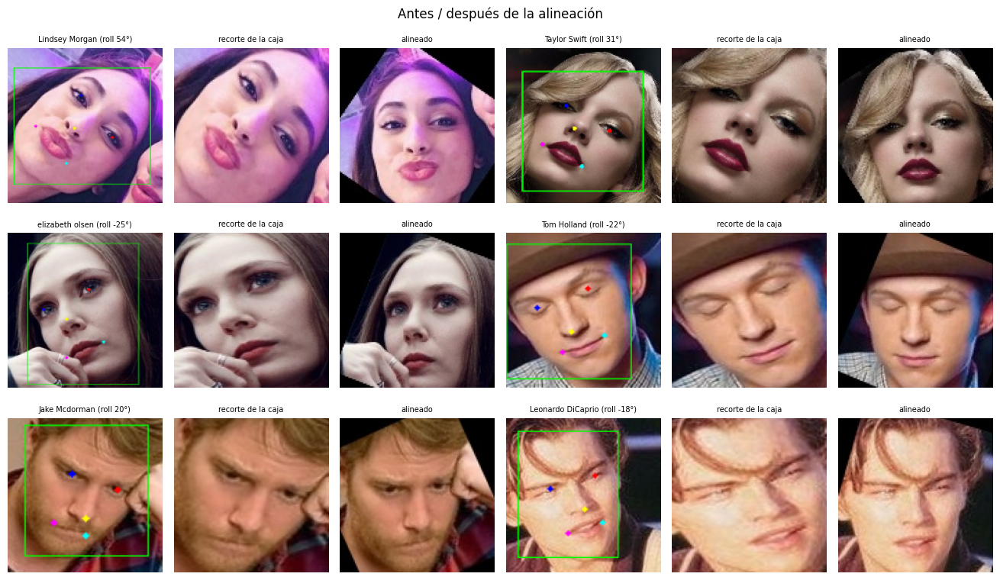

In [11]:
def draw(img, box, kps):
    img = img.copy()
    x1, y1, x2, y2 = map(int, box)
    t = max(1, img.shape[0] // 150)
    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), t)
    for (x, y), c in zip(kps, [(255, 0, 0), (0, 0, 255), (0, 255, 255), (255, 0, 255), (255, 255, 0)]):
        cv2.circle(img, (int(x), int(y)), 2 * t, c, -1)
    return img


face_rows = df.n_faces >= 1
k = np.array(df.loc[face_rows, "kps"].tolist())
eye_mid = (k[:, 0] + k[:, 1]) / 2
df.loc[face_rows, "roll"] = np.degrees(np.arctan2(k[:, 1, 1] - k[:, 0, 1], k[:, 1, 0] - k[:, 0, 0]))
df.loc[face_rows, "yaw"] = (k[:, 2, 0] - eye_mid[:, 0]) / np.linalg.norm(k[:, 1] - k[:, 0], axis=1)

demo_idx = df.loc[face_rows, "roll"].abs().sort_values(ascending=False).index[::300][:6]
imgs, titles = [], []
for r in df.loc[demo_idx].itertuples():
    img = read(r.raw_path)
    x1, y1, x2, y2 = map(int, r.box)
    imgs += [
        cv2.resize(draw(img, r.box, r.kps), (160, 160)),
        cv2.resize(img[max(y1, 0):y2, max(x1, 0):x2], (FACE_SIZE, FACE_SIZE)),
        read(ROOT / r.aligned_path),
    ]
    titles += [f"{r.identity} (roll {r.roll:.0f}°)", "recorte de la caja", "alineado"]
show_grid(imgs, titles, ncols=6, size=2.2, suptitle="Antes / después de la alineación")

### 3.4 Tamaño del rostro y pose

Con la caja medimos el tamaño del rostro, y con los landmarks estimamos la pose:
- **roll** (inclinación lateral): ángulo de la recta que une los ojos.
- **yaw** (giro izquierda/derecha), aproximado: desplazamiento horizontal de la nariz respecto del punto medio de los
  ojos, dividido por la distancia entre ojos. ≈0 es frontal; valores grandes, de perfil.

,count,mean,std,min,25%,50%,75%,max
face_min,17534.0,138.423,71.749,44.751,84.241,119.282,176.389,553.104
face_ratio,17534.0,0.540,0.090,0.252,0.478,0.536,0.598,0.971
det_score,17534.0,0.873,0.032,0.645,0.858,0.880,0.896,0.935
roll,17534.0,-1.108,10.145,-50.760,-5.793,-1.043,3.469,54.281
yaw,17534.0,0.001,0.227,-4.069,-0.096,0.004,0.096,6.361


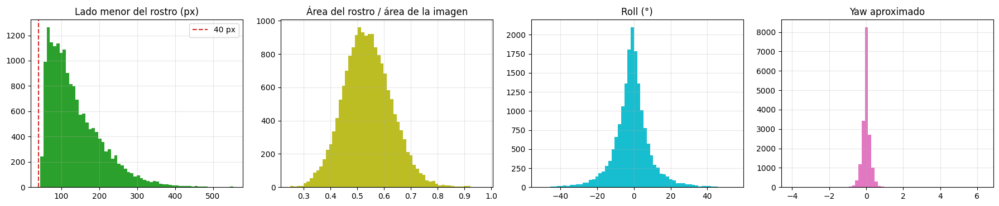

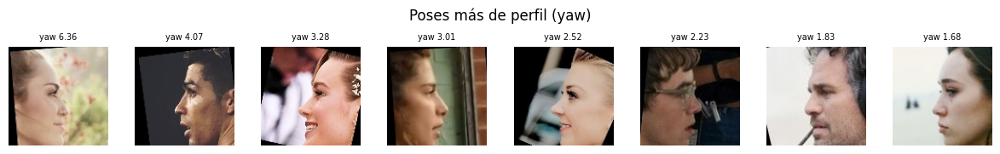

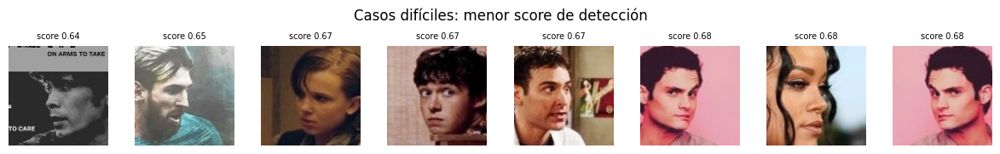

In [12]:
face = df[face_rows].copy()
face["face_min"] = face[["face_w", "face_h"]].min(axis=1)
face["face_ratio"] = face.face_w * face.face_h / (face.width * face.height)
display(face[["face_min", "face_ratio", "det_score", "roll", "yaw"]].describe().T)

fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
axes[0].hist(face.face_min, bins=60, color="tab:green")
axes[0].axvline(40, color="tab:red", ls="--", label="40 px")
axes[0].set_title("Lado menor del rostro (px)")
axes[0].legend()
axes[1].hist(face.face_ratio, bins=60, color="tab:olive")
axes[1].set_title("Área del rostro / área de la imagen")
axes[2].hist(face.roll, bins=60, color="tab:cyan")
axes[2].set_title("Roll (°)")
axes[3].hist(face.yaw, bins=60, color="tab:pink")
axes[3].set_title("Yaw aproximado")
plt.tight_layout()
plt.show()

prof = face.yaw.abs().nlargest(8)
show_grid([read(ROOT / face.at[i, "aligned_path"]) for i in prof.index], [f"yaw {v:.2f}" for v in prof],
          ncols=8, size=1.5, suptitle="Poses más de perfil (yaw)")
hard = face.nsmallest(8, "det_score")
show_grid([cv2.resize(read(p), (120, 120)) for p in hard.raw_path], [f"score {v:.2f}" for v in hard.det_score],
          ncols=8, size=1.5, suptitle="Casos difíciles: menor score de detección")

**Interpretación.**
- **Tamaño**: el rostro más chico mide 45 px de lado y la mediana 119 px. Ninguno está por debajo de los 40 px de la
  regla R4, y la cara ocupa en promedio el 54% de la imagen (confirma que son recortes ajustados).
- **Pose**: la gran mayoría es casi frontal (yaw entre −0,1 y 0,1 en el 50% central). Igual hay perfiles marcados: el
  ~9% tiene |yaw| > 0,35, y los casos extremos son perfiles completos donde un ojo no se ve. El roll tiene un desvío
  de 10° con extremos de ±54°: cabezas inclinadas que la alineación corrige.
- **Casos difíciles**: los scores de detección más bajos (≈0,65) corresponden a perfiles, caras con poca luz y fotos
  con texto superpuesto. Igual son detecciones correctas, así que no aplicamos un umbral de score más alto que 0,5.

La pose es la principal variación que la alineación **no** puede corregir: lleva los ojos a su lugar, pero no
convierte un perfil en una cara frontal. Es esperable que los modelos fallen más en estos casos (lo medimos en 5.4).

## 4. Control de calidad y limpieza

Las reglas se aplican **en orden** y cada imagen se descarta por la primera regla que cumple. Todas tienen umbrales
explícitos, así el filtrado es reproducible.

| # | Regla | Criterio |
|---|---|---|
| R1 | Archivo corrupto | `cv2.imread` devuelve `None` |
| R2 | Sin rostro | SCRFD no detecta ningún rostro con score ≥ 0.5 |
| R3 | Varios rostros sin uno principal | el segundo rostro tiene ≥ 50% del área del principal |
| R4 | Rostro chico | lado menor de la caja < 40 px |
| R5 | Rostro borroso | varianza del Laplaciano del rostro alineado < 20 |
| R6 | Exposición extrema | brillo medio del rostro alineado < 30 o > 225 |
| R7 | Duplicado dentro de la identidad | similitud coseno de embeddings > 0.90 con otra foto de la misma persona |
| R8 | Duplicado entre identidades | similitud > 0.90 con una imagen de **otra** identidad (etiqueta contradictoria: se descartan las dos) |
| R9 | Etiqueta errónea o rostro sin identidad | similitud con su propia identidad < 0.30, o más parecida a otra identidad que a la suya (ver sección 5) |

Para R7 y R8 necesitamos embeddings: usamos ArcFace (`w600k_r50.onnx`) como extractor, el mismo que se evalúa como
Modelo B en la notebook 2. Los embeddings quedan guardados y se reutilizan para el clustering.

In [13]:
BLUR_T = 20.0
DARK_T, BRIGHT_T = 30, 225
DUP_COS = 0.90


def face_quality(rel_path):
    img = read(ROOT / rel_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    small = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA)
    bits = (small[:, 1:] > small[:, :-1]).flatten()
    return {
        "face_blur": float(cv2.Laplacian(gray, cv2.CV_64F).var()),
        "face_brightness": float(gray.mean()),
        "dhash": int(np.packbits(bits).view(">i8")[0]),
    }


with ThreadPoolExecutor(8) as ex:
    q = list(tqdm(ex.map(face_quality, df.loc[face_rows, "aligned_path"]), total=int(face_rows.sum()), desc="calidad"))
q = pd.DataFrame(q, index=df.index[face_rows]).astype({"dhash": "Int64"})
df = df.drop(columns=["face_blur", "face_brightness", "dhash"], errors="ignore").join(q)

calidad:   0%|          | 0/17534 [00:00<?, ?it/s]

calidad:   1%|          | 213/17534 [00:00<00:08, 2124.19it/s]

calidad:   2%|▏         | 426/17534 [00:00<00:08, 2092.62it/s]

calidad:   4%|▎         | 636/17534 [00:00<00:08, 2077.39it/s]

calidad:   5%|▍         | 844/17534 [00:00<00:08, 2016.58it/s]

...

calidad:  96%|█████████▌| 16859/17534 [00:08<00:00, 1902.46it/s]

calidad:  97%|█████████▋| 17054/17534 [00:08<00:00, 1913.88it/s]

calidad:  98%|█████████▊| 17246/17534 [00:08<00:00, 1875.47it/s]

calidad:  99%|█████████▉| 17434/17534 [00:09<00:00, 1874.82it/s]

calidad: 100%|██████████| 17534/17534 [00:09<00:00, 1917.73it/s]

In [14]:
EMB_CACHE = PROC_DIR / "arcface_embeddings.npz"
arcface = ort.InferenceSession(str(MODELS_DIR / "w600k_r50.onnx"), providers=PROVIDERS)
arc_input = arcface.get_inputs()[0].name


def arcface_embed(rel_paths, batch_size=64):
    out = []
    for i in tqdm(range(0, len(rel_paths), batch_size), desc="embeddings ArcFace"):
        faces = [read(ROOT / p) for p in rel_paths[i : i + batch_size]]
        out.append(arcface.run(None, {arc_input: fp.to_model_input(faces)})[0])
    return fp.l2_normalize(np.concatenate(out)).astype(np.float32)


paths_with_face = df.loc[face_rows, "aligned_path"].tolist()
cache = np.load(EMB_CACHE) if EMB_CACHE.exists() else None
if cache is not None and cache["paths"].tolist() == paths_with_face:
    emb_all = cache["emb"]
    print("Embeddings cargados de cache")
else:
    t0 = time.perf_counter()
    emb_all = arcface_embed(paths_with_face)
    np.savez(EMB_CACHE, emb=emb_all, paths=np.array(paths_with_face))
    print(f"{len(emb_all)} embeddings en {time.perf_counter() - t0:.0f} s con {arcface.get_providers()[0]}")
emb_of = dict(zip(df.index[face_rows], range(len(emb_all))))


def emb(index):
    return emb_all[[emb_of[i] for i in index]]

Embeddings cargados de cache


### 4.1 ¿Hash perceptual o embeddings para detectar duplicados?

El enunciado sugiere un hash perceptual (dHash) o la similitud de embeddings. Probamos el dHash sobre el rostro
alineado y comparamos los pares que marca como duplicados (Hamming ≤ 4) con la similitud de sus embeddings. Cada fila
es un rango de similitud coseno.

,0.00–0.80,0.80–0.90,0.90–0.95,0.95–1.00
pares con Hamming ≤ 4,55,66,119,113


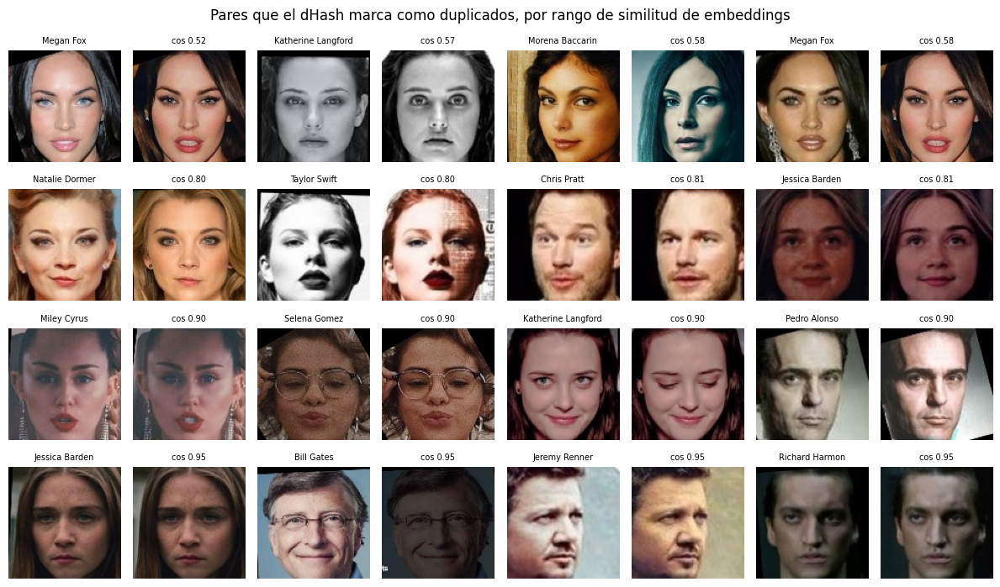

In [15]:
DUP_HAMMING = 4
pairs_h = []
for ident in rng.choice(sorted(df.identity.unique()), 30, replace=False):
    sub = df[(df.identity == ident) & face_rows]
    H = hamming_matrix(to_u64(sub.dhash), to_u64(sub.dhash))
    S = emb(sub.index) @ emb(sub.index).T
    for a, b in zip(*np.where(np.triu(H <= DUP_HAMMING, 1))):
        pairs_h.append((float(S[a, b]), sub.index[a], sub.index[b]))
pairs_h = pd.DataFrame(pairs_h, columns=["cos", "a", "b"])
bins = [(0, 0.8), (0.8, 0.9), (0.9, 0.95), (0.95, 1.01)]
display(pd.Series({f"{lo:.2f}–{min(hi, 1):.2f}": int(pairs_h.cos.between(lo, hi, inclusive="left").sum()) for lo, hi in bins},
                  name="pares con Hamming ≤ 4").to_frame().T)
imgs, titles = [], []
for lo, hi in bins:
    sel = pairs_h[pairs_h.cos.between(lo, hi, inclusive="left")].sort_values("cos").head(4)
    for r in sel.itertuples():
        imgs += [read(ROOT / df.at[r.a, "aligned_path"]), read(ROOT / df.at[r.b, "aligned_path"])]
        titles += [df.at[r.a, "identity"], f"cos {r.cos:.2f}"]
    imgs += [np.zeros((112, 112, 3), np.uint8)] * (8 - 2 * len(sel))
    titles += [""] * (8 - 2 * len(sel))
show_grid(imgs, titles, ncols=8, size=1.5, suptitle="Pares que el dHash marca como duplicados, por rango de similitud de embeddings")

**Conclusión.** El dHash sobre caras alineadas **no sirve**: como todas las caras alineadas tienen la misma estructura
(ojos, nariz y boca en el mismo lugar), el hash de 9×8 píxeles coincide en fotos distintas de la misma persona (filas
1 y 2: distinta ropa, distinto fondo, distinta sesión). En cambio, los pares con similitud de embeddings **> 0.90** son
siempre la misma foto con otro recorte, filtro o compresión (filas 3 y 4). Por eso R7 y R8 usan **solo la similitud de
embeddings con umbral 0.90** (más estricto que el 0.95 sugerido, porque las copias con filtro caen entre 0.90 y 0.95).

### 4.2 Umbral de nitidez

Miramos la distribución de la nitidez y ejemplos de rostros alrededor del umbral. La varianza del Laplaciano baja con
el desenfoque, pero **también con la oscuridad** (una cara oscura tiene bordes poco marcados aunque esté en foco).

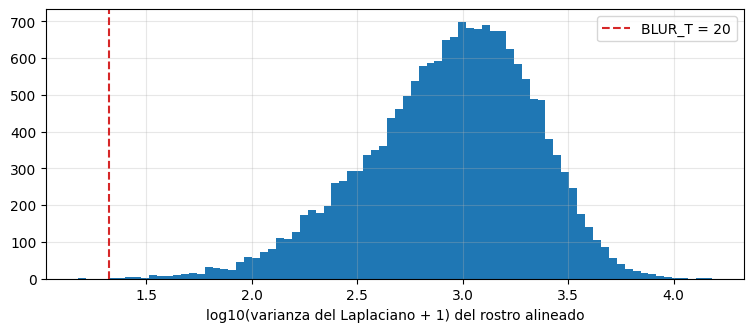

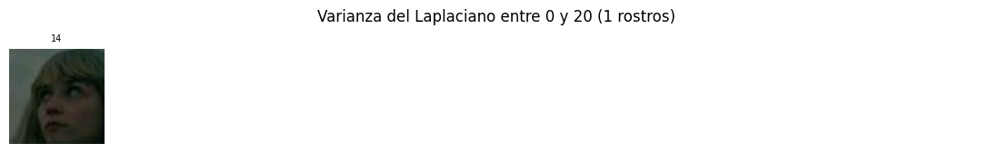

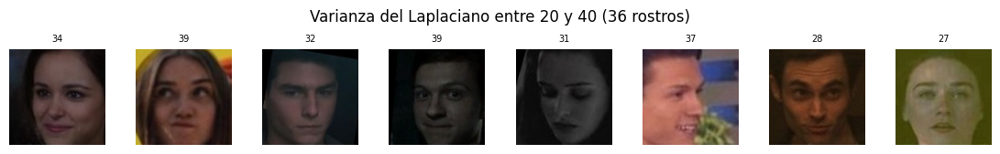

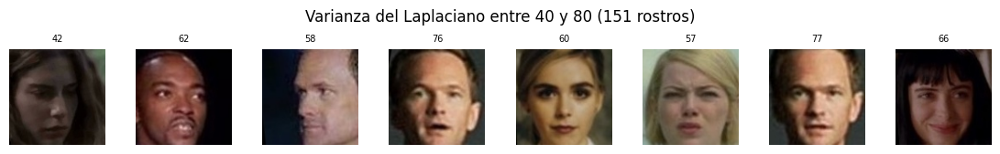

In [16]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(np.log10(df.face_blur.dropna() + 1), bins=80, color="tab:blue")
ax.axvline(np.log10(BLUR_T + 1), color="tab:red", ls="--", label=f"BLUR_T = {BLUR_T:.0f}")
ax.set_xlabel("log10(varianza del Laplaciano + 1) del rostro alineado")
ax.legend()
plt.show()

for lo, hi in [(0, BLUR_T), (BLUR_T, 2 * BLUR_T), (2 * BLUR_T, 4 * BLUR_T)]:
    sub = df[(df.face_blur >= lo) & (df.face_blur < hi)]
    sub = sub.sample(min(8, len(sub)), random_state=SEED)
    show_grid([read(ROOT / p) for p in sub.aligned_path], [f"{v:.0f}" for v in sub.face_blur], ncols=8, size=1.4,
              suptitle=f"Varianza del Laplaciano entre {lo:.0f} y {hi:.0f} ({len(df[(df.face_blur >= lo) & (df.face_blur < hi)])} rostros)")

**Conclusión.** En una primera versión usamos 40 como umbral, pero los rostros entre 20 y 40 **no están borrosos:
están oscuros**, y siguen siendo útiles (la app también va a recibir fotos con poca luz). Con `BLUR_T = 20` la regla
descarta solo los casos realmente inservibles. Pins casi no tiene fotos movidas: el autor ya las había filtrado.

### 4.3 Aplicación de las reglas

In [17]:
def near_duplicates_within(sub):
    """Recorre de mayor a menor rostro y marca como duplicado todo lo muy parecido a una imagen que ya se conservó."""
    sub = sub.sort_values("face_w", ascending=False)
    idx = sub.index.to_numpy()
    E = emb(idx)
    S = E @ E.T
    removed, pairs = set(), []
    for a in range(len(idx)):
        if idx[a] in removed:
            continue
        for b in range(a + 1, len(idx)):
            if idx[b] not in removed and S[a, b] > DUP_COS:
                removed.add(idx[b])
                pairs.append((idx[a], idx[b], float(S[a, b])))
    return removed, pairs


df["discard"] = None
rules = [
    ("R1 archivo corrupto", ~df.readable),
    ("R2 sin rostro", df.n_faces == 0),
    ("R3 varios rostros sin principal", df.second_area_ratio >= 0.5),
    ("R4 rostro < 40 px", df[["face_w", "face_h"]].min(axis=1) < 40),
    ("R5 rostro borroso", df.face_blur < BLUR_T),
    ("R6 exposición extrema", (df.face_brightness < DARK_T) | (df.face_brightness > BRIGHT_T)),
]
for name, mask in rules:
    df.loc[mask.fillna(False).astype(bool) & df.discard.isna(), "discard"] = name

dup_pairs = []
for ident, sub in tqdm(df[df.discard.isna()].groupby("identity"), desc="duplicados por identidad"):
    removed, pairs = near_duplicates_within(sub)
    df.loc[list(removed), "discard"] = "R7 duplicado (misma identidad)"
    dup_pairs += pairs

keep = df.index[df.discard.isna()].to_numpy()
E = emb(keep)
labels = df.loc[keep, "identity"].to_numpy()
cross_pairs = []
for s in range(0, len(keep), 2048):
    S = E[s : s + 2048] @ E.T
    for a, b in zip(*np.where(S > DUP_COS)):
        if s + a < b and labels[s + a] != labels[b]:
            cross_pairs.append((keep[s + a], keep[b], float(S[a, b])))
for a, b, _ in cross_pairs:
    df.loc[[a, b], "discard"] = "R8 duplicado entre identidades"
print(f"Pares duplicados dentro de identidades: {len(dup_pairs)} · entre identidades: {len(cross_pairs)}")

duplicados por identidad:   0%|          | 0/105 [00:00<?, ?it/s]

duplicados por identidad:  17%|█▋        | 18/105 [00:00<00:00, 173.03it/s]

duplicados por identidad:  40%|████      | 42/105 [00:00<00:00, 211.69it/s]

duplicados por identidad:  64%|██████▍   | 67/105 [00:00<00:00, 227.01it/s]

duplicados por identidad:  87%|████████▋ | 91/105 [00:00<00:00, 228.84it/s]

duplicados por identidad: 100%|██████████| 105/105 [00:00<00:00, 222.48it/s]

Pares duplicados dentro de identidades: 1245 · entre identidades: 1


R1 archivo corrupto: ninguna imagen
R2 sin rostro: ninguna imagen


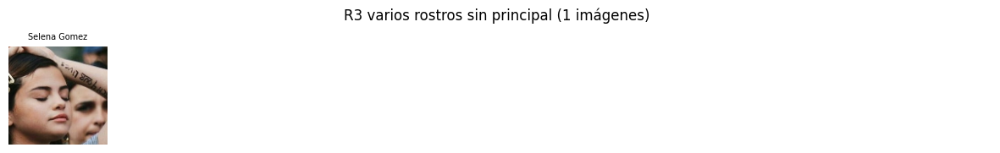

R4 rostro < 40 px: ninguna imagen


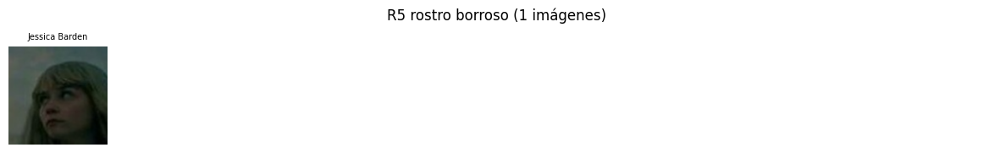

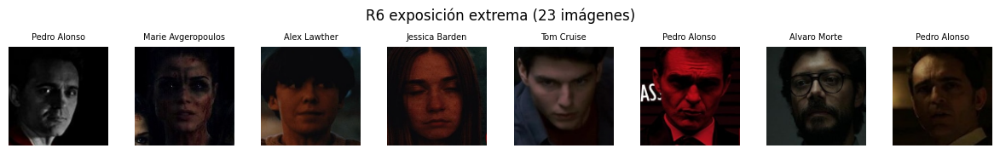

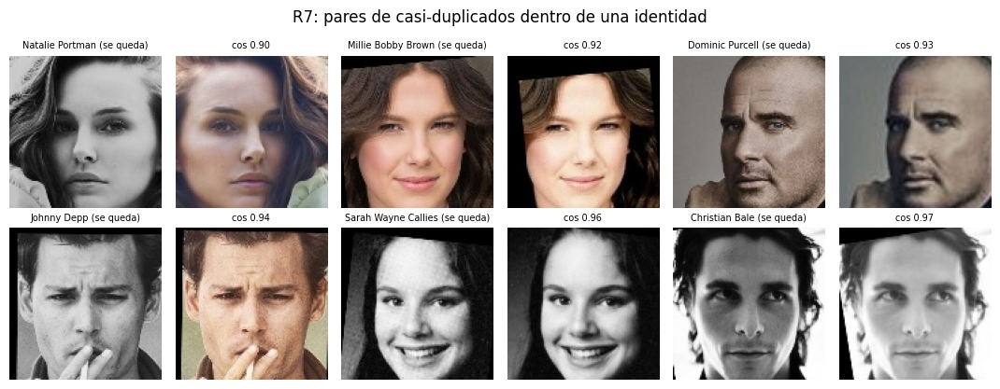

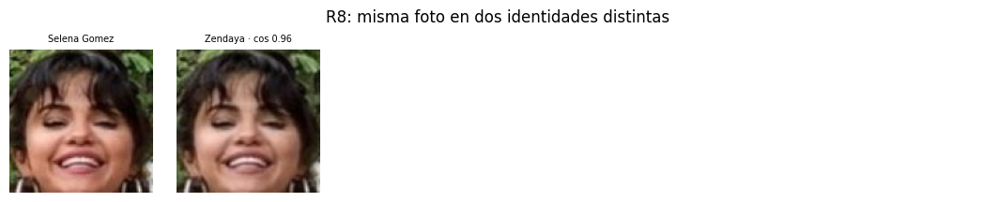

In [18]:
def show_rule(name, n=8):
    sub = df[df.discard == name]
    if len(sub) == 0:
        print(f"{name}: ninguna imagen")
        return
    sub = sub.sample(min(n, len(sub)), random_state=SEED)
    imgs = [
        cv2.resize(read(r.raw_path), (120, 120)) if r.readable else np.zeros((120, 120, 3), np.uint8)
        for r in sub.itertuples()
    ]
    show_grid(imgs, list(sub.identity), ncols=8, size=1.5, suptitle=f"{name} ({(df.discard == name).sum()} imágenes)")


for name in [r[0] for r in rules]:
    show_rule(name)

imgs, titles = [], []
for a, b, s in sorted(dup_pairs, key=lambda p: p[2])[:: max(1, len(dup_pairs) // 6)][:6]:
    imgs += [read(ROOT / df.at[a, "aligned_path"]), read(ROOT / df.at[b, "aligned_path"])]
    titles += [f"{df.at[a, 'identity']} (se queda)", f"cos {s:.2f}"]
show_grid(imgs, titles, ncols=6, size=1.8, suptitle="R7: pares de casi-duplicados dentro de una identidad")

imgs, titles = [], []
for a, b, s in cross_pairs[:6]:
    imgs += [read(ROOT / df.at[a, "aligned_path"]), read(ROOT / df.at[b, "aligned_path"])]
    titles += [df.at[a, "identity"], f"{df.at[b, 'identity']} · cos {s:.2f}"]
show_grid(imgs, titles, ncols=6, size=1.8, suptitle="R8: misma foto en dos identidades distintas")

**Interpretación.**
- **R1–R4 casi no descartan nada**: no hay archivos corruptos, con el borde todos tienen rostro, solo una imagen tiene
  dos caras del mismo tamaño y ningún rostro mide menos de 40 px. Era esperable: el autor del dataset ya había
  recortado cada foto alrededor de una cara.
- **R5 y R6** sacan 24 rostros inservibles (casi negros o quemados).
- **R7 es la regla que más pesa: 1.245 imágenes (7,1%) son casi-duplicados** (la misma foto con otro recorte,
  filtro, color o compresión, como se ve en la grilla). Es típico de un scraping de Pinterest, donde la misma foto se
  vuelve a subir muchas veces. Si no las sacáramos, una copia podría caer en train y la otra en test, y las métricas
  quedarían infladas (el modelo "reconocería" una foto que ya vio).
- **R8** encontró una foto de Selena Gomez guardada también en la carpeta de Zendaya: etiqueta contradictoria, se
  descartan las dos copias.

## 5. Clustering exploratorio

Usamos los embeddings de ArcFace de las imágenes que pasaron R1–R8 para analizar el dataset:
1. ¿Hay imágenes **mal etiquetadas** (lejos de su propia identidad y cerca de otra)?
2. ¿Qué identidades se **mezclan**?
3. ¿Hay **sub-clusters** por condiciones de captura (blanco y negro, perfil)?
4. ¿Qué tan bien recupera un algoritmo de clustering las identidades reales (ARI, NMI, silhouette)?

### 5.1 Outliers y etiquetas erróneas

Para cada imagen calculamos la similitud coseno con el **centroide de su identidad sin contarse a sí misma**
(leave-one-out) y con el centroide más cercano de **otra** identidad. Marcamos como outlier (R9) si:
- está **más cerca de otra identidad** que de la suya (etiqueta errónea entre personas del dataset), o
- su similitud con la propia identidad es **< 0.30**: no se parece a nadie, así que es otra persona que no está en
  el dataset o un rostro que no muestra la identidad (máscara, maquillaje de personaje).

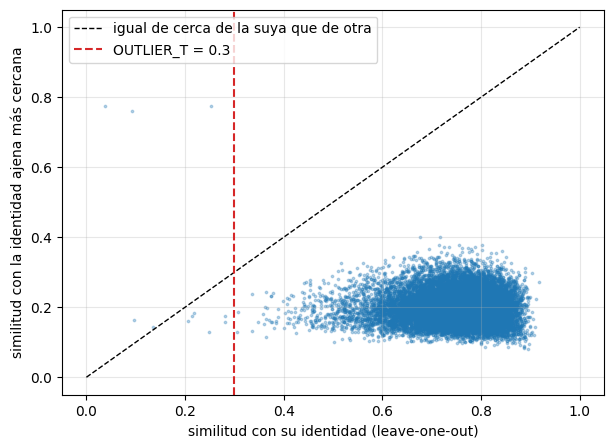

Outliers (R9): 11 imágenes (5 más cerca de otra identidad)


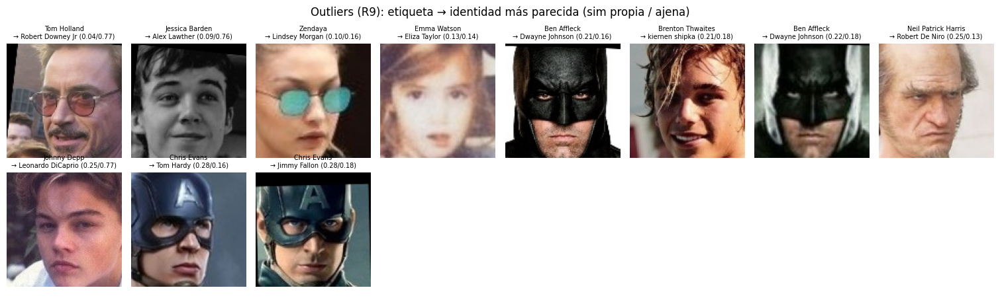

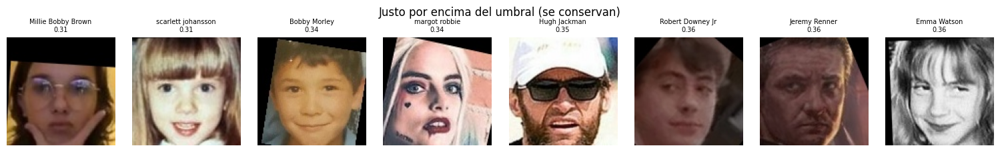

In [19]:
OUTLIER_T = 0.30


def identity_similarities(sub):
    """Similitud con el centroide propio (leave-one-out) y con el centroide ajeno más cercano."""
    E = emb(sub.index)
    names = sorted(sub.identity.unique())
    y = sub.identity.map({n: i for i, n in enumerate(names)}).to_numpy()
    sums = np.stack([E[y == c].sum(0) for c in range(len(names))])
    sim_own = (E * fp.l2_normalize(sums[y] - E)).sum(1)
    sim_c = E @ fp.l2_normalize(sums).T
    sim_c[np.arange(len(E)), y] = -1
    return sim_own, sim_c.max(1), [names[j] for j in sim_c.argmax(1)]


cur = df[df.discard.isna()].copy()
cur["sim_own"], cur["sim_other"], cur["nearest_other"] = identity_similarities(cur)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(cur.sim_own, cur.sim_other, s=3, alpha=0.3)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="igual de cerca de la suya que de otra")
ax.axvline(OUTLIER_T, color="tab:red", ls="--", label=f"OUTLIER_T = {OUTLIER_T}")
ax.set_xlabel("similitud con su identidad (leave-one-out)")
ax.set_ylabel("similitud con la identidad ajena más cercana")
ax.legend()
plt.show()

outliers = cur[(cur.sim_own < OUTLIER_T) | (cur.sim_other > cur.sim_own)]
print(f"Outliers (R9): {len(outliers)} imágenes "
      f"({(outliers.sim_other > outliers.sim_own).sum()} más cerca de otra identidad)")
worst = outliers.nsmallest(16, "sim_own")
show_grid(
    [read(ROOT / p) for p in worst.aligned_path],
    [f"{r.identity}\n→ {r.nearest_other} ({r.sim_own:.2f}/{r.sim_other:.2f})" for r in worst.itertuples()],
    ncols=8, size=1.9, suptitle="Outliers (R9): etiqueta → identidad más parecida (sim propia / ajena)",
)
near = cur[(cur.sim_own >= OUTLIER_T) & (cur.sim_own < 0.40)].nsmallest(8, "sim_own")
show_grid([read(ROOT / p) for p in near.aligned_path], [f"{r.identity}\n{r.sim_own:.2f}" for r in near.itertuples()],
          ncols=8, size=1.9, suptitle="Justo por encima del umbral (se conservan)")
df.loc[outliers.index, "discard"] = "R9 etiqueta errónea o rostro sin identidad"

**Interpretación.** El gráfico muestra una nube compacta (similitud propia entre 0.5 y 0.9, ajena < 0.4) y unos pocos
puntos aislados. R9 descarta **11 imágenes**, y al mirarlas se ven dos tipos de problema:
- **Etiquetas erróneas (5)**: una foto de Robert Downey Jr. en la carpeta de Tom Holland (compañeros en Marvel), una de
  Alex Lawther en la de Jessica Barden (co-protagonistas de una serie), un DiCaprio joven en la de Johnny Depp, y
  personas que no son Zendaya ni Brenton Thwaites. Son errores típicos de un scraping: la foto aparece al buscar a un
  actor porque sale con alguien de su elenco.
- **Rostros sin información de identidad (6)**: Ben Affleck como Batman, Chris Evans como Capitán América (máscaras
  que tapan media cara), Neil Patrick Harris caracterizado como el Conde Olaf, y una foto de Emma Watson de bebé.

Las **descartamos en lugar de corregirlas**: son pocas, y reasignar una etiqueta a mano (por ejemplo, mover la foto de
Downey Jr. a su carpeta) sería introducir una decisión manual difícil de reproducir. Las imágenes justo por encima del
umbral (maquillaje fuerte, fotos de infancia) se conservan: son casos difíciles pero de la persona correcta.

### 5.2 Proyección t-SNE y algoritmos de clustering

Proyectamos a 2D con t-SNE (PCA a 50 dimensiones primero, que es lo recomendado para acelerar y quitar ruido).
Después comparamos tres algoritmos contra las etiquetas reales:
- **K-Means** con k = 105 (cantidad real de identidades), sobre los embeddings normalizados (en la esfera unitaria la
  distancia euclídea es equivalente a la coseno).
- **Aglomerativo** (linkage promedio, distancia coseno), k = 105.
- **DBSCAN** (distancia coseno): no recibe k, así que muestra cuántos grupos "naturales" hay y cuántos puntos quedan
  como ruido.

El aglomerativo y DBSCAN calculan la matriz de distancias completa (O(n²) en memoria), así que corren sobre una
muestra estratificada de 40 imágenes por identidad. K-Means corre sobre todo el conjunto.

t-SNE: 26 s


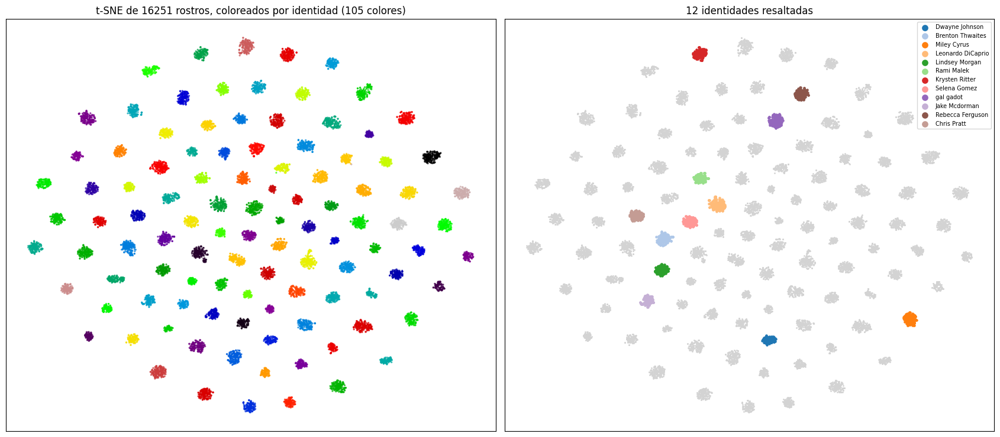

In [20]:
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score

cur = df[df.discard.isna()].copy()
cur["sim_own"], cur["sim_other"], cur["nearest_other"] = identity_similarities(cur)
E = emb(cur.index)
ids = sorted(cur.identity.unique())
y = cur.identity.map({n: i for i, n in enumerate(ids)}).to_numpy()

t0 = time.perf_counter()
Z = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(
    PCA(50, random_state=SEED).fit_transform(E)
)
print(f"t-SNE: {time.perf_counter() - t0:.0f} s")

highlight = list(rng.choice(ids, 12, replace=False))
hl = cur.identity.isin(highlight).to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))
axes[0].scatter(Z[:, 0], Z[:, 1], c=y, cmap="nipy_spectral", s=2, alpha=0.6)
axes[0].set_title(f"t-SNE de {len(E)} rostros, coloreados por identidad (105 colores)")
axes[1].scatter(Z[~hl, 0], Z[~hl, 1], s=1, c="lightgray", zorder=0)
for j, name in enumerate(highlight):
    m = (cur.identity == name).to_numpy()
    axes[1].scatter(Z[m, 0], Z[m, 1], s=5, label=name, color=plt.cm.tab20(j))
axes[1].set_title("12 identidades resaltadas")
axes[1].legend(fontsize=7, markerscale=3, loc="best")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

In [21]:
sample_idx = cur.groupby("identity", group_keys=False).apply(lambda g: g.sample(min(40, len(g)), random_state=SEED)).index
m = cur.index.isin(sample_idx)
Es, ys = E[m], y[m]

t0 = time.perf_counter()
km = KMeans(n_clusters=len(ids), n_init=5, random_state=SEED).fit_predict(E)
agg = AgglomerativeClustering(n_clusters=len(ids), metric="cosine", linkage="average").fit_predict(Es)
db = DBSCAN(eps=0.5, min_samples=5, metric="cosine").fit_predict(Es)
print(f"Clustering: {time.perf_counter() - t0:.0f} s")


def clus_metrics(name, true, pred, X):
    mask = pred >= 0
    n_clusters = len(set(pred[mask]))
    return {
        "algoritmo": name,
        "imágenes": len(X),
        "clusters": n_clusters,
        "ruido": f"{(~mask).mean():.1%}",
        "ARI": adjusted_rand_score(true, pred),
        "NMI": normalized_mutual_info_score(true, pred),
        "silhouette": silhouette_score(X[mask], pred[mask], metric="cosine", sample_size=min(8000, mask.sum()),
                                       random_state=SEED) if n_clusters > 1 else np.nan,
    }


clus_table = pd.DataFrame(
    [
        clus_metrics("etiquetas reales (referencia)", y, y, E),
        clus_metrics("K-Means (k=105)", y, km, E),
        clus_metrics("Aglomerativo promedio (k=105)", ys, agg, Es),
        clus_metrics("DBSCAN (eps=0.5, coseno)", ys, db, Es),
    ]
).set_index("algoritmo")
display(clus_table)

Clustering: 9 s


,imágenes,clusters,ruido,ARI,NMI,silhouette
algoritmo,,,,,,
etiquetas reales (referencia),16251,105,0.0%,1.000,1.000,0.481
K-Means (k=105),16251,105,0.0%,0.971,0.993,0.453
Aglomerativo promedio (k=105),4200,105,0.0%,1.000,1.000,0.485
"DBSCAN (eps=0.5, coseno)",4200,105,1.4%,0.975,0.989,0.491


**Interpretación.** El t-SNE muestra **105 islas bien separadas**, una por identidad: con los embeddings de ArcFace el
dataset curado es muy "limpio". Los tres algoritmos recuperan casi perfectamente las identidades reales:
- **K-Means**: ARI 0.97 y NMI 0.99. No llega a 1 porque K-Means con k = 105 a veces junta dos identidades en un
  cluster y parte otra en dos (depende de la inicialización), aunque las identidades estén separadas.
- **Aglomerativo**: ARI = 1.00 sobre la muestra de 40 imágenes por persona: el linkage promedio con distancia coseno
  recupera exactamente las 105 personas.
- **DBSCAN**: sin saber cuántas personas hay, encuentra **105 grupos** y deja solo el 1,4% como ruido (las fotos más
  atípicas de cada persona).
- **Silhouette ≈ 0.48** con las etiquetas reales: los grupos están separados, pero no son puntuales (hay variación
  dentro de cada persona por pose, edad e iluminación).

Esto también fija una expectativa para la notebook 2: con un buen extractor, las 105 personas son separables. Si la
CNN custom no logra algo parecido, no es por el dataset sino por el modelo.

### 5.3 ¿Qué identidades se mezclan?

Dos miradas: los pares de identidades con **centroides más parecidos**, y los **clusters de K-Means que juntan dos
identidades** (el cluster tiene al menos 10 imágenes de cada una).

,identidad A,identidad B,similitud de centroides
0,Lili Reinhart,amber heard,0.336
1,Taylor Swift,scarlett johansson,0.325
2,Natalie Portman,Sarah Wayne Callies,0.322
3,Natalie Portman,gal gadot,0.312
4,Taylor Swift,gal gadot,0.308
5,Emma Stone,margot robbie,0.299
6,Jennifer Lawrence,Ursula Corbero,0.296
7,Emilia Clarke,Jessica Barden,0.286
8,Johnny Depp,Leonardo DiCaprio,0.285
9,Emilia Clarke,Miley Cyrus,0.283


Similitud media entre centroides de identidades distintas: 0.023
Clusters de K-Means que mezclan ≥ 2 identidades (≥ 10 imágenes de cada una): 4
  cluster 7: Chris Evans (152), Chris Hemsworth (147)
  cluster 38: Inbar Lavi (115), Morgan Freeman (94)
  cluster 70: Lionel Messi (85), Robert De Niro (146)
  cluster 87: Lili Reinhart (141), Maria Pedraza (116)


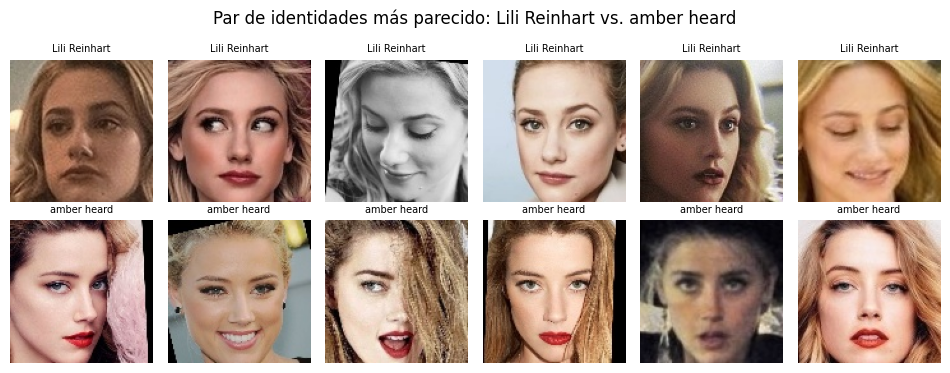

In [22]:
cent = fp.l2_normalize(np.stack([E[y == c].mean(0) for c in range(len(ids))]))
C = cent @ cent.T
iu = np.triu_indices(len(ids), 1)
top_pairs = np.argsort(C[iu])[::-1][:10]
pair_df = pd.DataFrame(
    [{"identidad A": ids[iu[0][p]], "identidad B": ids[iu[1][p]], "similitud de centroides": C[iu][p]} for p in top_pairs]
)
display(pair_df)
print(f"Similitud media entre centroides de identidades distintas: {C[iu].mean():.3f}")

ct = pd.crosstab(km, cur.identity)
mixed = [(c, row[row >= 10].index.tolist()) for c, row in ct.iterrows() if (row >= 10).sum() >= 2]
print(f"Clusters de K-Means que mezclan ≥ 2 identidades (≥ 10 imágenes de cada una): {len(mixed)}")
for c, names in mixed[:10]:
    print(f"  cluster {c}: " + ", ".join(f"{n} ({ct.loc[c, n]})" for n in names))

a, b = pair_df.iloc[0, 0], pair_df.iloc[0, 1]
imgs = [read(ROOT / p) for p in cur[cur.identity == a].aligned_path.head(6)] + [
    read(ROOT / p) for p in cur[cur.identity == b].aligned_path.head(6)
]
show_grid(imgs, [a] * 6 + [b] * 6, ncols=6, size=1.6, suptitle=f"Par de identidades más parecido: {a} vs. {b}")

**Interpretación.** Los pares de identidades más parecidos tienen sentido visual: Lili Reinhart y Amber Heard, Taylor
Swift y Scarlett Johansson, Natalie Portman y Gal Gadot, Emma Stone y Margot Robbie, Johnny Depp y Leonardo DiCaprio.
Son personas del **mismo género, edad, tono de piel y estilo** (rubias de ojos claros, morochas de rasgos finos). Igual
la similitud entre sus centroides es baja (≤ 0.34, con una media de 0.02 entre todos los pares): para ArcFace siguen
siendo personas claramente distintas. Estos pares son los candidatos naturales a falsos positivos en la notebook 2.

Los 4 clusters "mezclados" de K-Means no coinciden con los pares más parecidos (por ejemplo, Lionel Messi con
Robert De Niro): son el artefacto de K-Means descrito arriba, no una confusión real entre identidades.

### 5.4 ¿Hay sub-clusters por condiciones de captura?

Si el embedding dependiera de cómo se sacó la foto (y no solo de quién es), las fotos en blanco y negro o de perfil
quedarían más lejos de su propia identidad. Lo medimos comparando la similitud con el propio centroide por grupo.

,count,mean,50%,25%
grupo,,,,
blanco y negro,1143.0,0.721,0.732,0.675
"color, frontal",13645.0,0.753,0.767,0.711
perfil (|yaw| > 0.35),1463.0,0.709,0.720,0.665


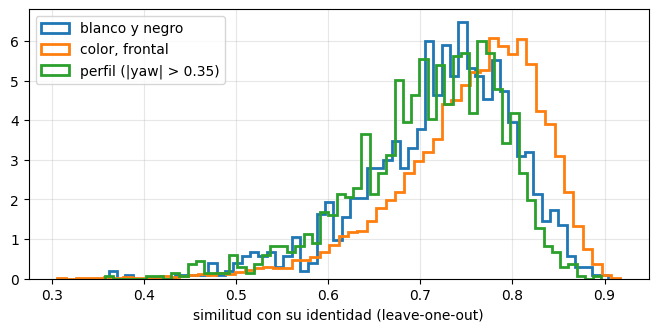

In [23]:
cur["grupo"] = np.select(
    [cur.grayscale_content, cur.yaw.abs() > 0.35], ["blanco y negro", "perfil (|yaw| > 0.35)"], "color, frontal"
)
display(cur.groupby("grupo").sim_own.describe()[["count", "mean", "50%", "25%"]])

fig, ax = plt.subplots(figsize=(8, 3.5))
for g, sub in cur.groupby("grupo"):
    ax.hist(sub.sim_own, bins=60, density=True, histtype="step", lw=2, label=g)
ax.set_xlabel("similitud con su identidad (leave-one-out)")
ax.legend()
plt.show()

**Interpretación.** Las fotos en **blanco y negro** (similitud media 0.72) y de **perfil** (0.71) quedan algo más lejos
de su identidad que las fotos color frontales (0.75): la distribución se corre ~0.03–0.04 hacia la izquierda. Es
decir, el embedding sí se ve afectado por las condiciones de captura, pero **no forman sub-clusters separados**: siguen
dentro de la isla de su persona en el t-SNE. Para la app significa que los perfiles y las fotos en blanco y negro van a
tener scores más bajos y son los que más riesgo tienen de caer por debajo del umbral (falsos `unknown`). Para la CNN
custom, justifica incluir `ToGray` y pequeñas rotaciones en la augmentation.

## 6. Data augmentation

El pipeline está en `src/lib/augmentation.py` y se aplica **solo en train** (la notebook 2 lo usa en el `Dataset` de
entrenamiento; validación y test ven los rostros alineados tal cual). Trabaja sobre el rostro **ya alineado**, por eso
las transformaciones geométricas son chicas: simulan los errores normales de los landmarks, no poses nuevas.

| Transformación | Incluida | Por qué |
|---|---|---|
| Flip horizontal (p=0.5) | ✅ | La cara es casi simétrica: el espejo es la misma persona. Duplica la variedad de poses. |
| Rotación ±10°, traslación ±4%, escala ±5% | ✅ | Errores típicos de la alineación con 5 landmarks. |
| Brillo / contraste ±25%, saturación | ✅ | Interiores, exteriores, flash, filtros. |
| Escala de grises (p=0.05) | ✅ | Hay fotos en blanco y negro en el dataset y en la vida real. |
| Blur gaussiano / de movimiento | ✅ | Fotos fuera de foco o movidas (dentro de lo que dejó pasar R5). |
| Ruido gaussiano | ✅ | Sensores de celular con poca luz. |
| Compresión JPEG (calidad 40–95) | ✅ | Fotos recomprimidas por redes sociales y mensajería. |
| Coarse dropout (1–2 parches) | ✅ | Simula oclusiones: anteojos, manos, pelo, barbijo. Obliga a no depender de una sola zona. |
| Flip vertical | ❌ | Una cara cabeza abajo no ocurre en la app; el detector ya la normalizaría. |
| Rotaciones de 90° | ❌ | Ídem: la alineación ya corrige la rotación. |
| Distorsiones elásticas / perspectiva fuerte | ❌ | Cambian la geometría del rostro (distancia entre ojos, forma de la mandíbula), que es justamente lo que identifica a la persona. |
| Cambios de tono (hue) fuertes | ❌ | Cambian el tono de piel: inventa variaciones irreales y puede reforzar sesgos. Solo ±5. |

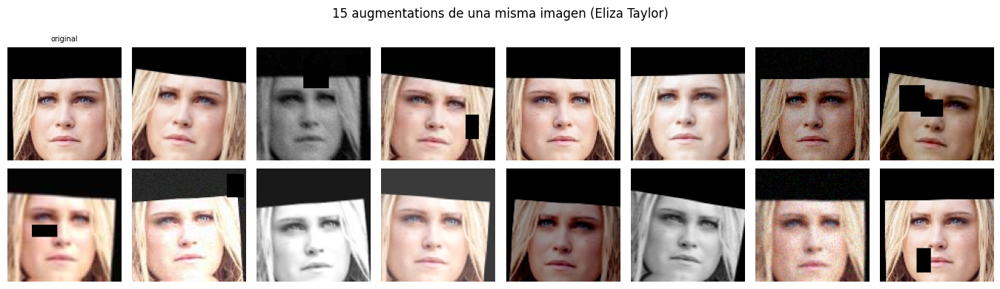

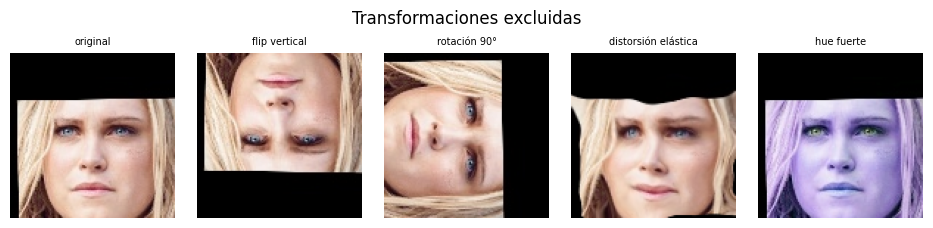

In [24]:
aug = build_train_augmentation(FACE_SIZE)
aug.set_random_seed(SEED)
ex_row = cur.sample(1, random_state=7).iloc[0]
base = read(ROOT / ex_row.aligned_path)
show_grid([base] + [aug(image=base)["image"] for _ in range(15)], ["original"] + [""] * 15, ncols=8, size=1.7,
          suptitle=f"15 augmentations de una misma imagen ({ex_row.identity})")

excluded = [
    ("flip vertical", cv2.flip(base, 0)),
    ("rotación 90°", cv2.rotate(base, cv2.ROTATE_90_CLOCKWISE)),
    ("distorsión elástica", A.ElasticTransform(alpha=120, sigma=6, p=1)(image=base)["image"]),
    ("hue fuerte", A.HueSaturationValue(hue_shift_limit=(60, 60), sat_shift_limit=0, val_shift_limit=0, p=1)(image=base)["image"]),
]
show_grid([base] + [e[1] for e in excluded], ["original"] + [e[0] for e in excluded], ncols=5, size=1.9,
          suptitle="Transformaciones excluidas")

**Desbalance.** No usamos la augmentation para sobremuestrear clases chicas. El desbalance es moderado (2,8× entre
la identidad más grande y la más chica después de la limpieza) y, además, al modelo no le pedimos clasificar bien a
las 75 personas de entrenamiento sino producir buenos embeddings para personas nuevas: una clase con algunas fotos
menos sigue aportando señal suficiente. Las alternativas serían *weighted sampling* (ver más seguido las clases
chicas) o *class weights* en la pérdida. Ambas cambian cuánto pesa cada persona en el gradiente, pero con este nivel
de desbalance el efecto esperado es chico, y preferimos dedicar los experimentos de la notebook 2 a decisiones que
pesan más (cabeza de la pérdida, pooling y augmentation). Lo que sí hacemos es **estratificar por identidad** al
partir, para que todas las clases tengan la misma proporción en train, validación y test.

## 7. Partición de datos (splits)

Separamos dos escenarios:

- **Closed-set (identificación):** las mismas personas en train y test, con fotos distintas. Sirve para entrenar la
  CNN como clasificador y medir accuracy de clasificación.
- **Open-set (verificación):** personas **que el modelo nunca vio**. Es el escenario real de la app (se registra
  gente nueva después del entrenamiento), así que es donde se reportan las métricas principales.

Estrategia (semilla 42):

1. **Por identidad**: 105 identidades → **75 de entrenamiento**, **10 de validación open-set** y **20 de test
   open-set**. Las 10 de validación sirven para calibrar el umbral y elegir hiperparámetros con gente no vista, sin
   tocar el test.
2. **Por imagen, dentro de las 75 de entrenamiento** (estratificado por identidad): 80% `train`, 10% `val_closed`
   (early stopping) y 10% `test_closed` (accuracy de clasificación).

Como ya eliminamos los casi-duplicados (R7) **antes** de partir, una foto y su copia no pueden caer en splits
distintos. Igual lo verificamos al final.

In [25]:
from sklearn.model_selection import train_test_split

final = df[df.discard.isna()].copy()
id_order = np.array(sorted(final.identity.unique()))
np.random.default_rng(SEED).shuffle(id_order)
train_ids, val_ids, test_ids = id_order[:75], id_order[75:85], id_order[85:]

final["split"] = None
final.loc[final.identity.isin(val_ids), "split"] = "val_open"
final.loc[final.identity.isin(test_ids), "split"] = "test_open"
tr = final[final.identity.isin(train_ids)]
tr_idx, rest_idx = train_test_split(tr.index, test_size=0.2, stratify=tr.identity, random_state=SEED)
val_idx, test_idx = train_test_split(rest_idx, test_size=0.5, stratify=tr.loc[rest_idx, "identity"], random_state=SEED)
final.loc[tr_idx, "split"] = "train"
final.loc[val_idx, "split"] = "val_closed"
final.loc[test_idx, "split"] = "test_closed"

label_map = {name: i for i, name in enumerate(sorted(train_ids))}
final["label"] = final.identity.map(label_map).fillna(-1).astype(int)

cols = ["aligned_path", "raw_path", "identity", "label"]
for name, sub in final.groupby("split"):
    sub[cols].to_csv(SPLITS_DIR / f"{name}.csv", index=False)
(SPLITS_DIR / "meta.json").write_text(
    json.dumps(
        {
            "seed": SEED,
            "face_size": FACE_SIZE,
            "detector": "SCRFD det_10g.onnx (buffalo_l)",
            "det_input_size": DET_INPUT_SIZE,
            "det_score_threshold": DET_SCORE_THRESHOLD,
            "det_pad": DET_PAD,
            "alignment": "insightface norm_crop (plantilla ArcFace, 5 landmarks)",
            "normalization": "BGR->RGB, (x - 127.5) / 127.5, NCHW",
            "quality": {"min_face": 40, "blur_t": BLUR_T, "dark_t": DARK_T, "bright_t": BRIGHT_T,
                        "dup_cos": DUP_COS, "outlier_t": OUTLIER_T},
            "train_ids": sorted(train_ids.tolist()),
            "val_open_ids": sorted(val_ids.tolist()),
            "test_open_ids": sorted(test_ids.tolist()),
            "label_map": label_map,
        },
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)
print("Splits guardados en", SPLITS_DIR.relative_to(ROOT), "->", sorted(p.name for p in SPLITS_DIR.iterdir()))

Splits guardados en data/splits -> ['meta.json', 'test_closed.csv', 'test_open.csv', 'train.csv', 'val_closed.csv', 'val_open.csv']


### 7.1 Verificación de fuga de datos

In [26]:
order = ["train", "val_closed", "test_closed", "val_open", "test_open"]
paths = {s: set(final.loc[final.split == s, "raw_path"]) for s in order}
id_sets = {s: set(final.loc[final.split == s, "identity"]) for s in order}
pos = {s: (final.split == s).to_numpy() for s in order}
Ef = emb(final.index)
max_cos = {s: float((Ef[pos[s]] @ Ef[pos["train"]].T).max()) for s in order[1:]}

checks = pd.DataFrame(
    [
        ("ningún archivo está en dos splits",
         all(not (paths[a] & paths[b]) for i, a in enumerate(order) for b in order[i + 1:])),
        ("identidades de val_open y test_open no están en train (ni entre sí)",
         not (id_sets["train"] & id_sets["val_open"]) and not (id_sets["train"] & id_sets["test_open"])
         and not (id_sets["val_open"] & id_sets["test_open"])),
    ]
    + [(f"ninguna imagen de {s} es casi-duplicado de una de train (máx. similitud {v:.3f} ≤ {DUP_COS})", v <= DUP_COS)
       for s, v in max_cos.items()],
    columns=["verificación", "ok"],
)
display(checks)

,verificación,ok
0,ningún archivo está en dos splits,True
1,identidades de val_open y test_open no están e...,True
2,ninguna imagen de val_closed es casi-duplicado...,True
3,ninguna imagen de test_closed es casi-duplicad...,True
4,ninguna imagen de val_open es casi-duplicado d...,True
5,ninguna imagen de test_open es casi-duplicado ...,True


## 8. Ética, privacidad y licencias

- **Datos biométricos.** Un rostro identifica a una persona de forma permanente: si se filtra, no se puede "cambiar"
  como una contraseña. La **Ley 25.326 de Protección de Datos Personales** (Argentina) los trata como datos
  personales, y por identificar de forma unívoca entran en la categoría de **datos sensibles**: su tratamiento
  requiere **consentimiento libre, expreso e informado** del titular, una finalidad determinada y medidas de
  seguridad. El titular tiene derecho de acceso, rectificación y supresión.
- **Licencia del dataset.** Kaggle lo publica como CC0, pero las fotos son de Pinterest: el que las subió no tiene
  los derechos de autor de los fotógrafos ni puede ceder la imagen de las celebridades. Por eso lo usamos solo con fines
  académicos, **no subimos las imágenes al repositorio** (`data/*` está en el `.gitignore`) y no publicamos el
  dataset procesado.
- **Modelos preentrenados.** Los modelos de InsightFace (SCRFD y ArcFace de `buffalo_l`) tienen licencia
  **solo para uso no comercial / investigación**. Un TP académico entra en ese uso; un producto comercial no.
- **Fotos propias.** No usamos fotos de terceros. Para la demo de la app usamos fotos de los integrantes del grupo,
  con su consentimiento, que tampoco se suben al repositorio.
- **Sesgos.** El dataset está compuesto por celebridades, mayormente jóvenes, de Estados Unidos y Europa y de piel
  clara, con fotos producidas. Un modelo entrenado o calibrado acá puede tener **más falsos positivos o negativos en
  otros grupos demográficos** (está documentado en la literatura, por ejemplo en las evaluaciones FRVT del NIST).
  Además el umbral calibrado con estas fotos puede no servir para cámaras de baja calidad.
- **Riesgos del reconocimiento facial.** Vigilancia masiva sin consentimiento, identificación de manifestantes,
  errores que recaen sobre personas inocentes (un falso positivo en un contexto policial es grave) y pérdida del
  anonimato en el espacio público. En Argentina, el Sistema de Reconocimiento Facial de Prófugos de la Ciudad de
  Buenos Aires fue suspendido por la justicia en 2022 por falta de controles. Una app como esta debería usarse solo
  con consentimiento de las personas registradas, con un umbral conservador y siempre con revisión humana de los
  resultados.

## 9. Resumen final

In [27]:
rule_names = [r[0] for r in rules] + ["R7 duplicado (misma identidad)", "R8 duplicado entre identidades",
                                      "R9 etiqueta errónea o rostro sin identidad"]
discard_table = df.discard.value_counts().reindex(rule_names).fillna(0).astype(int).to_frame("imágenes descartadas")
discard_table.loc["total descartadas"] = discard_table["imágenes descartadas"].sum()
discard_table.loc["conservadas"] = int(df.discard.isna().sum())
discard_table["% del dataset"] = (discard_table["imágenes descartadas"] / len(df) * 100).round(2)
display(discard_table)

split_table = final.groupby("split").agg(identidades=("identity", "nunique"), imágenes=("identity", "size")).reindex(order)
split_table["escenario"] = ["closed-set", "closed-set", "closed-set", "open-set", "open-set"]
split_table["uso"] = [
    "entrenar la CNN (con augmentation)",
    "early stopping / selección de época",
    "accuracy de clasificación closed-set",
    "calibrar el umbral y elegir modelo",
    "métricas finales (verificación e identificación)",
]
split_table.loc["total"] = [final.identity.nunique(), len(final), "", ""]
display(split_table)

per_id = final.groupby("identity").size()
print(f"Imágenes por identidad después de la limpieza: mín {per_id.min()}, mediana {per_id.median():.0f}, máx {per_id.max()}")

,imágenes descartadas,% del dataset
discard,,
R1 archivo corrupto,0,0.00
R2 sin rostro,0,0.00
R3 varios rostros sin principal,1,0.01
R4 rostro < 40 px,0,0.00
R5 rostro borroso,1,0.01
R6 exposición extrema,23,0.13
R7 duplicado (misma identidad),1245,7.10
R8 duplicado entre identidades,2,0.01
R9 etiqueta errónea o rostro sin identidad,11,0.06


,identidades,imágenes,escenario,uso
split,,,,
train,75,9138,closed-set,entrenar la CNN (con augmentation)
val_closed,75,1142,closed-set,early stopping / selección de época
test_closed,75,1143,closed-set,accuracy de clasificación closed-set
val_open,10,1774,open-set,calibrar el umbral y elegir modelo
test_open,20,3054,open-set,métricas finales (verificación e identificación)
total,105,16251,,


Imágenes por identidad después de la limpieza: mín 82, mediana 160, máx 213


**Resumen.**
- Partimos de **17.534 imágenes de 105 personas** y conservamos **16.251 (92,7%)**. Casi todo lo descartado son
  casi-duplicados (7,1%); el resto de las reglas sacan menos del 0,3% en total.
- Hallazgos que cambiaron el pipeline: **SCRFD necesita un borde** para detectar primeros planos (sin él falla en el
  91% de las imágenes), el **dHash sobre caras alineadas da falsos duplicados** (usamos embeddings) y la **varianza del
  Laplaciano confunde oscuridad con blur** (umbral 20).
- El dataset tenía **errores de etiqueta** (fotos de compañeros de elenco en la carpeta equivocada) y rostros con
  máscaras o caracterizaciones; los detectamos con los embeddings y los sacamos.
- Splits: **75 personas para entrenar** (9.138 / 1.142 / 1.143 imágenes en train / val_closed / test_closed),
  **10 personas no vistas para calibrar** (1.774 imágenes) y **20 personas no vistas para el test final** (3.054
  imágenes), sin fuga de datos entre splits.
- Todo queda en `data/processed` (rostros alineados 112×112 y embeddings) y `data/splits` (CSV + `meta.json` con
  semilla, umbrales y configuración del pipeline), listo para `2-train.ipynb`.